# Peak-Based Graph Attention Network (PeakGAT) for Seismic Wildlife Classification

This notebook implements a novel pipeline that converts seismic ground-vibration recordings into
sparse, interpretable graphs and classifies wildlife species using a Graph Attention Network (GAT).

**Dataset:** SeisSavanna (Szenicer et al., 2021) — CC BY 4.0

**Pipeline:**
1. Load spectrogram from NetCDF dataset
2. Average frequency axis → 1D energy envelope
3. Z-score normalization
4. Peak detection (footstep transients → graph nodes)
5. Extract 5D node features per peak
6. Construct dual-edge graph (temporal + k-NN)
7. Train PeakGAT model
8. Evaluate and visualize results

---
## 1. Imports & Environment Setup

In [34]:
# Core libraries
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


# Signal processing & ML
import xarray as xr
from scipy.signal import find_peaks
from sklearn.neighbors import kneighbors_graph
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tqdm import tqdm

# PyTorch & PyTorch Geometric
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATConv, global_mean_pool, global_max_pool

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Number of GPUs: {torch.cuda.device_count()}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

PyTorch version: 2.8.0+cu128
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB
Number of GPUs: 8
Using device: cuda


---
## 2. Configuration & Hyperparameters

All tunable parameters are defined here in one place for easy experimentation.

In [35]:
# ── All hyperparameters in one place ──
CONFIG = {
    # Data
    'data_url': "https://www.dropbox.com/scl/fo/avwuo0jx9tjp6167auk2b/APb9q6h8NCNX71b5F0ENiyA/dset_allspec_150/dset_allspec_150_chunks_clean.nc?rlkey=xunpptuv7xn396ylyuiw3q8xw&dl=1",
    'data_file': 'PROJECT/dset_allspec_150_chunks_clean.nc',

    # Peak Detection
    'prominence': 0.05,       # Minimum peak prominence (sensitivity)
    'distance': 10,           # Minimum samples between peaks

    # Graph Construction
    'k_neighbors': 5,         # k-NN structural edges

    # Model Architecture
    'hidden_dim': 64,         # GAT hidden layer width
    'heads': 4,               # Number of attention heads
    'dropout': 0.4,           # Dropout rate in classifier

    # Training
    'batch_size': 64,
    'learning_rate': 0.001,
    'weight_decay': 1e-4,
    'epochs': 100,
    'test_size': 0.2,
    'seed': 42,
}

# Set seeds for reproducibility
torch.manual_seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])

print("Configuration loaded:")
for key, val in CONFIG.items():
    if key != 'data_url':
        print(f"  {key}: {val}")

Configuration loaded:
  data_file: PROJECT/dset_allspec_150_chunks_clean.nc
  prominence: 0.05
  distance: 10
  k_neighbors: 5
  hidden_dim: 64
  heads: 4
  dropout: 0.4
  batch_size: 64
  learning_rate: 0.001
  weight_decay: 0.0001
  epochs: 100
  test_size: 0.2
  seed: 42


---
## 3. Data Loading

Download and inspect the SeisSavanna NetCDF dataset.

In [36]:
# Download dataset if not already present
file_path = CONFIG['data_file']

if not os.path.exists(file_path):
    print(f"Downloading dataset to {file_path}...")
    urllib.request.urlretrieve(CONFIG['data_url'], file_path)
    print("Download complete!")
else:
    print(f"{file_path} already exists.")

PROJECT/dset_allspec_150_chunks_clean.nc already exists.


In [37]:
# Load and inspect the dataset
ds = xr.open_dataset(file_path)

print("Dataset variables:")
print(list(ds.data_vars))
print(f"\nDimensions: {ds.sizes}")

Dataset variables:
['chunk', 'class', 'distance', 'seis', 'image']

Dimensions: Frozen({'traces': 70637, 'comp': 3, 'time': 2048, 'side': 128})


In [38]:
# Identify the spectrogram and label keys
spec_key = 'spectrogram' if 'spectrogram' in ds.data_vars else list(ds.data_vars.keys())[0]
label_key = 'label' if 'label' in ds.data_vars else list(ds.data_vars.keys())[1]

spectrograms = ds[spec_key].values
raw_labels = ds[label_key].values

# Remap labels to contiguous range [0, 1, 2, ...]
unique_classes = np.unique(raw_labels)
label_map = {old: new for new, old in enumerate(unique_classes)}
labels = np.array([label_map[l] for l in raw_labels])
num_classes = len(unique_classes)

print(f"Spectrogram key: '{spec_key}', shape: {spectrograms.shape}")
print(f"Label key: '{label_key}', unique classes: {num_classes}")
print(f"Original labels: {unique_classes}")
print(f"Remapped to:     {list(range(num_classes))}")
print(f"Class distribution: {dict(zip(range(num_classes), [int((labels==i).sum()) for i in range(num_classes)]))}")


Spectrogram key: 'chunk', shape: (70637, 3, 2048)
Label key: 'class', unique classes: 11
Original labels: [ 0  1  2  3  4  5  6  7  8  9 11]
Remapped to:     [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Class distribution: {0: 2073, 1: 62493, 2: 164, 3: 2, 4: 271, 5: 769, 6: 4321, 7: 42, 8: 10, 9: 488, 10: 4}


### 3.1 Visualize a Sample Spectrogram

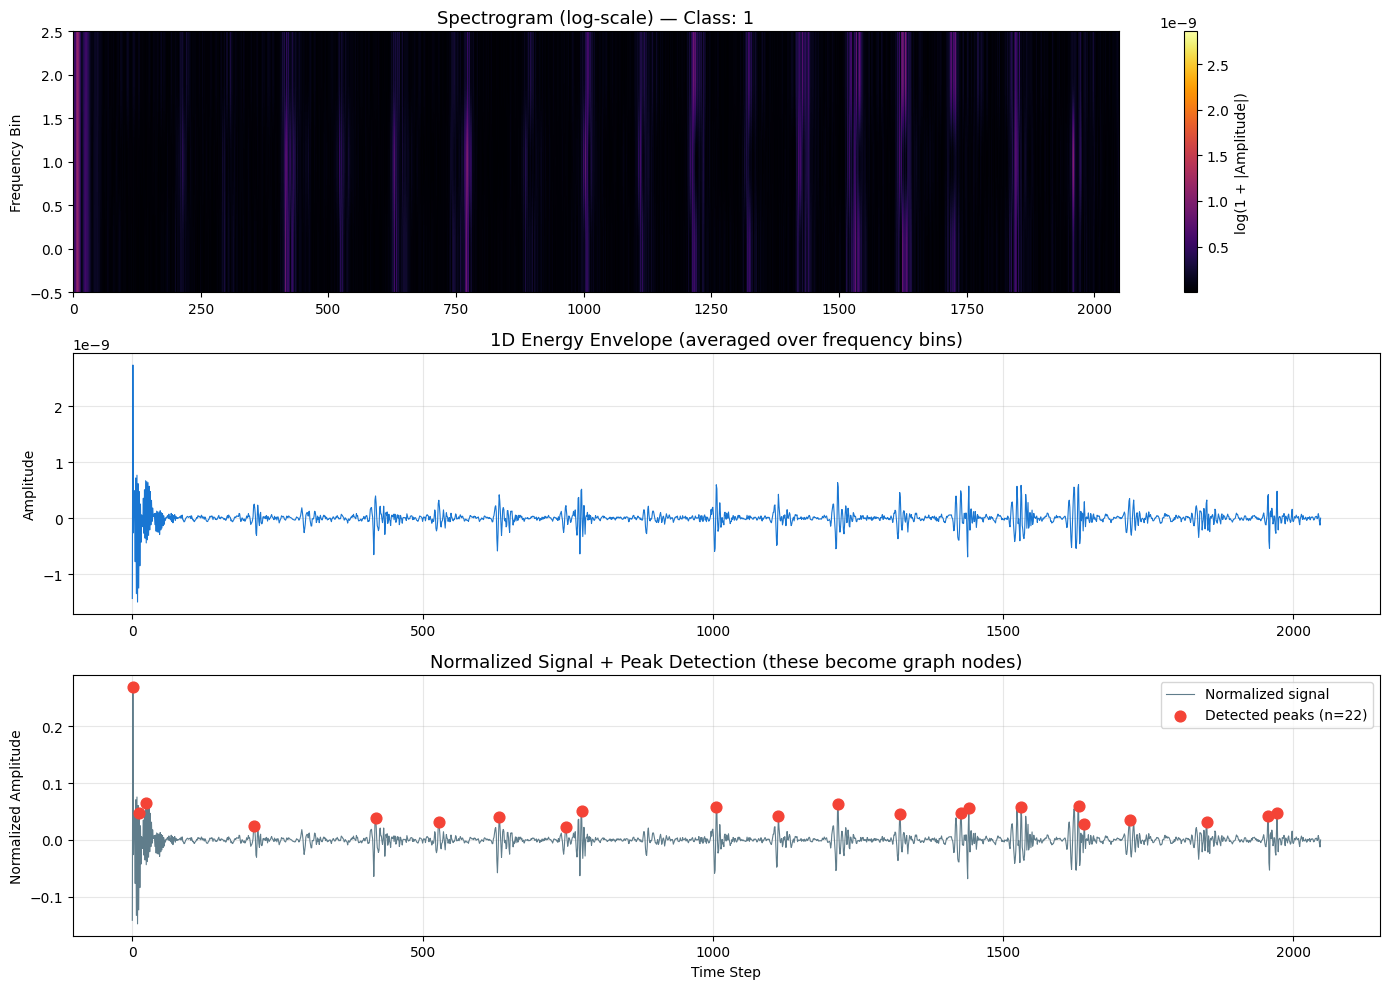

Shape: (3, 2048) | Peaks detected: 22


In [39]:
# Visualize a sample in 3 views
try:
    sample_spec = ds[spec_key].isel(time_chunk=0).values if 'time_chunk' in ds.dims else ds[spec_key][0].values
    sample_label = ds[label_key].isel(time_chunk=0).values if 'time_chunk' in ds.dims else ds[label_key][0].values

    fig, axes = plt.subplots(3, 1, figsize=(14, 10))

    # 1. Spectrogram with log scale for better contrast
    spec_plot = np.log1p(np.abs(sample_spec))  # log(1 + |x|) for better visibility
    im = axes[0].imshow(spec_plot, aspect='auto', origin='lower', cmap='inferno')
    axes[0].set_title(f'Spectrogram (log-scale) — Class: {sample_label}', fontsize=13)
    axes[0].set_ylabel('Frequency Bin')
    plt.colorbar(im, ax=axes[0], label='log(1 + |Amplitude|)')

    # 2. Energy envelope (averaged over frequency)
    energy = np.mean(sample_spec, axis=0)
    axes[1].plot(energy, color='#1976D2', linewidth=0.8)
    axes[1].set_title('1D Energy Envelope (averaged over frequency bins)', fontsize=13)
    axes[1].set_ylabel('Amplitude')
    axes[1].grid(True, alpha=0.3)

    # 3. Normalized signal with detected peaks
    norm_signal = (energy - np.mean(energy)) / (np.std(energy) + 1e-8)
    peaks, _ = find_peaks(norm_signal, prominence=CONFIG['prominence'], distance=CONFIG['distance'])
    axes[2].plot(norm_signal, color='#607D8B', linewidth=0.8, label='Normalized signal')
    axes[2].scatter(peaks, norm_signal[peaks], c='#F44336', s=60, zorder=5,
                    label=f'Detected peaks (n={len(peaks)})')
    axes[2].set_title('Normalized Signal + Peak Detection (these become graph nodes)', fontsize=13)
    axes[2].set_xlabel('Time Step')
    axes[2].set_ylabel('Normalized Amplitude')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
    print(f"Shape: {sample_spec.shape} | Peaks detected: {len(peaks)}")

except Exception as e:
    print(f"Could not plot. Error: {e}")


---
## 4. Signal Preprocessing & Peak Detection

Each spectrogram is converted to a 1D energy envelope by averaging across frequency bins,
then normalized using z-score standardization. Peaks (footstep transients) are detected
using SciPy's `find_peaks` with configurable prominence and distance thresholds.

In [40]:
def preprocess_signal(spectrogram):
    """
    Convert a 2D spectrogram into a normalized 1D energy envelope.
    
    Steps:
        1. Average across frequency bins → 1D signal
        2. Z-score normalization
    
    Args:
        spectrogram (np.ndarray): 2D array of shape (F, T).
    
    Returns:
        np.ndarray: Normalized 1D signal of shape (T,).
    """
    signal = np.mean(spectrogram, axis=0)
    signal = (signal - np.mean(signal)) / (np.std(signal) + 1e-8)
    return signal

print("Signal preprocessing function defined.")

Signal preprocessing function defined.


### 4.1 Visualize the Preprocessing Pipeline on a Sample

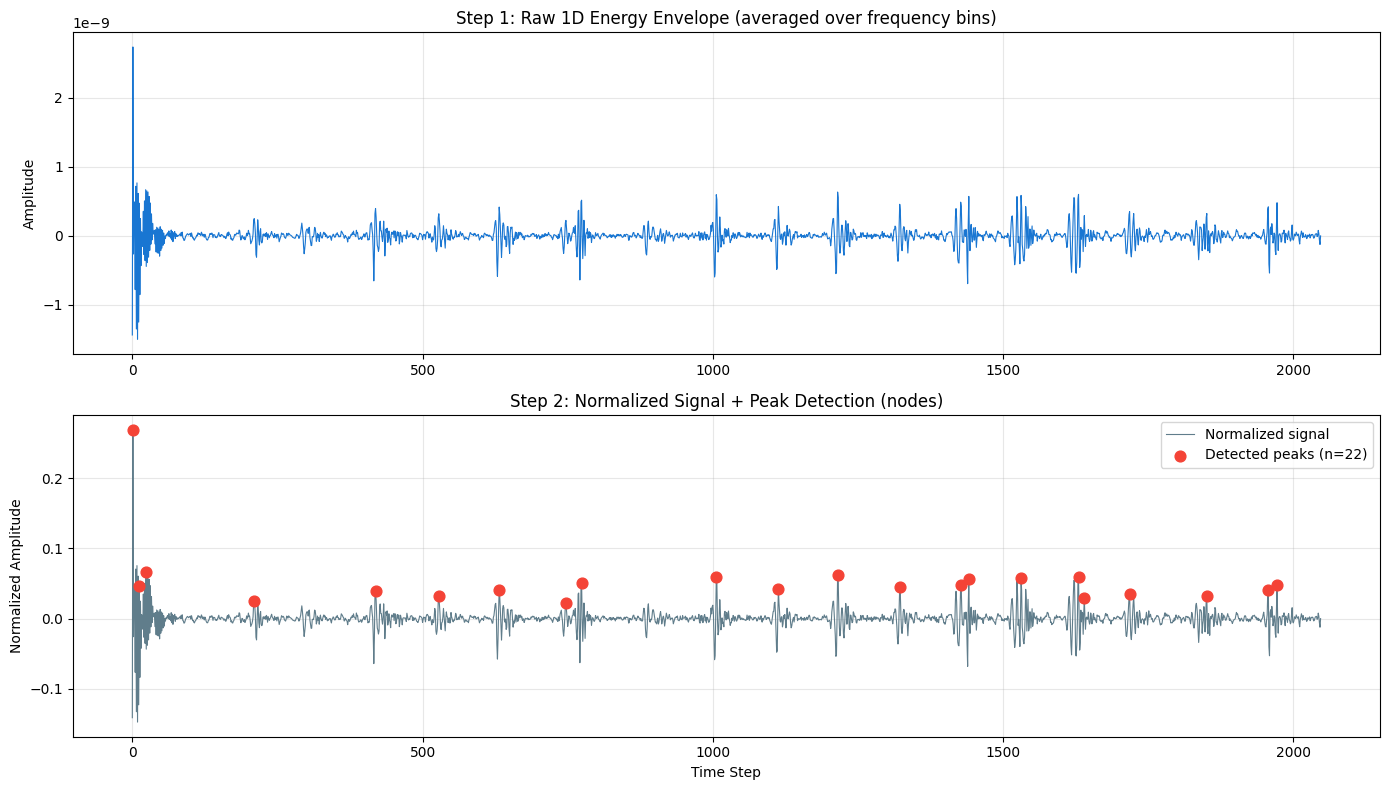

Sample 0: 22 peaks detected → 22 graph nodes


In [41]:
# Demonstrate the full preprocessing on one sample
sample_idx = 0
sample_signal = preprocess_signal(spectrograms[sample_idx])
sample_peaks, sample_props = find_peaks(sample_signal, 
                                         prominence=CONFIG['prominence'], 
                                         distance=CONFIG['distance'])

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Raw averaged signal
raw_signal = np.mean(spectrograms[sample_idx], axis=0)
axes[0].plot(raw_signal, color='#1976D2', linewidth=0.8)
axes[0].set_title('Step 1: Raw 1D Energy Envelope (averaged over frequency bins)')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True, alpha=0.3)

# Normalized signal with detected peaks
axes[1].plot(sample_signal, color='#607D8B', linewidth=0.8, label='Normalized signal')
axes[1].scatter(sample_peaks, sample_signal[sample_peaks], 
                c='#F44336', s=60, zorder=5, label=f'Detected peaks (n={len(sample_peaks)})')
axes[1].set_title('Step 2: Normalized Signal + Peak Detection (nodes)')
axes[1].set_xlabel('Time Step')
axes[1].set_ylabel('Normalized Amplitude')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print(f"Sample {sample_idx}: {len(sample_peaks)} peaks detected → {len(sample_peaks)} graph nodes")

---
## 5. Graph Construction

Each detected peak becomes a **node** in the graph with a 5D feature vector:

| Feature | Description |
|---------|-------------|
| Peak Height | Amplitude of the signal at the peak |
| Prominence | How much the peak stands out from surroundings |
| Local Std Dev | Variability in a ±10-sample window |
| Local Energy | Sum of squared amplitudes in the window |
| Normalized Position | Temporal position (t/T) within the signal |

**Edges** are constructed using a dual-topology:
- **Temporal edges:** Connect consecutive peaks (i ↔ i+1) to capture gait rhythm
- **k-NN edges:** Connect morphologically similar peaks in feature space

In [42]:
def extract_peaks_and_build_graph(signal, label):
    """
    Convert a normalized 1D seismic signal into a PyG graph.
    
    Args:
        signal (np.ndarray): Normalized 1D signal of shape (T,).
        label (int): Integer class label for the animal species.
    
    Returns:
        torch_geometric.data.Data or None: Graph with node features and
        dual-edge topology. Returns None if fewer than 2 peaks detected.
    """
    # ── 1. Peak Detection ──
    peaks, props = find_peaks(signal, 
                              prominence=CONFIG['prominence'], 
                              distance=CONFIG['distance'])
    
    if len(peaks) < 2:
        return None  # Cannot form a graph with fewer than 2 nodes
    
    # ── 2. Extract 5D Node Features ──
    node_features = []
    for i, p in enumerate(peaks):
        window = signal[max(0, p - 10) : min(len(signal), p + 10)]
        feat = [
            signal[p],                                                    # Peak height
            props['prominences'][i] if 'prominences' in props else 0,     # Prominence
            np.std(window) if len(window) > 0 else 0,                     # Local std dev
            np.sum(window ** 2) if len(window) > 0 else 0,                # Local energy
            p / len(signal),                                               # Normalized position
        ]
        node_features.append(feat)
    
    x = torch.tensor(node_features, dtype=torch.float)
    
    # ── 3. Build Edges ──
    edges = []
    n = len(peaks)
    
    # A. Temporal edges (bidirectional chain: i ↔ i+1)
    for i in range(n - 1):
        edges.append([i, i + 1])
        edges.append([i + 1, i])
    
    # B. k-NN similarity edges (connect morphologically similar peaks)
    if n > CONFIG['k_neighbors']:
        A = kneighbors_graph(x.numpy(), 
                            n_neighbors=CONFIG['k_neighbors'], 
                            mode='connectivity', 
                            include_self=False)
        rows, cols = A.nonzero()
        for r, c in zip(rows, cols):
            edges.append([r, c])
    
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    y = torch.tensor([label], dtype=torch.long)
    
    return Data(x=x, edge_index=edge_index, y=y)

print("Graph construction function defined.")

Graph construction function defined.


### 5.1 Process Entire Dataset into Graphs

In [43]:
# ── Filter to Top 4 classes only ──
from collections import Counter

# Count class distribution
all_labels = [g.y.item() for g in graph_dataset]
counts = Counter(all_labels)
top_4 = [cls for cls, _ in counts.most_common(4)]

print(f"Top 4 classes: {top_4}")
for cls in top_4:
    print(f"  Class {cls}: {counts[cls]} samples")

# Filter dataset
filtered_dataset = [g for g in graph_dataset if g.y.item() in top_4]

# Remap labels to [0, 1, 2, 3]
remap = {old: new for new, old in enumerate(sorted(top_4))}
for g in filtered_dataset:
    g.y = torch.tensor([remap[g.y.item()]], dtype=torch.long)

graph_dataset = filtered_dataset
num_classes = 4

print(f"\nFiltered dataset: {len(graph_dataset)} graphs, {num_classes} classes")
print(f"Label mapping: {remap}")


Top 4 classes: [1, 3, 0, 2]
  Class 1: 48975 samples
  Class 3: 3385 samples
  Class 0: 1613 samples
  Class 2: 508 samples

Filtered dataset: 54481 graphs, 4 classes
Label mapping: {0: 0, 1: 1, 2: 2, 3: 3}


### 5.2 Graph Dataset Statistics

Graph Dataset Statistics:
  Total graphs:      54481
  Avg nodes/graph:   68.4 ± 51.9
  Avg edges/graph:   475.7 ± 364.9
  Min/Max nodes:     2 / 150
  Node features:     5


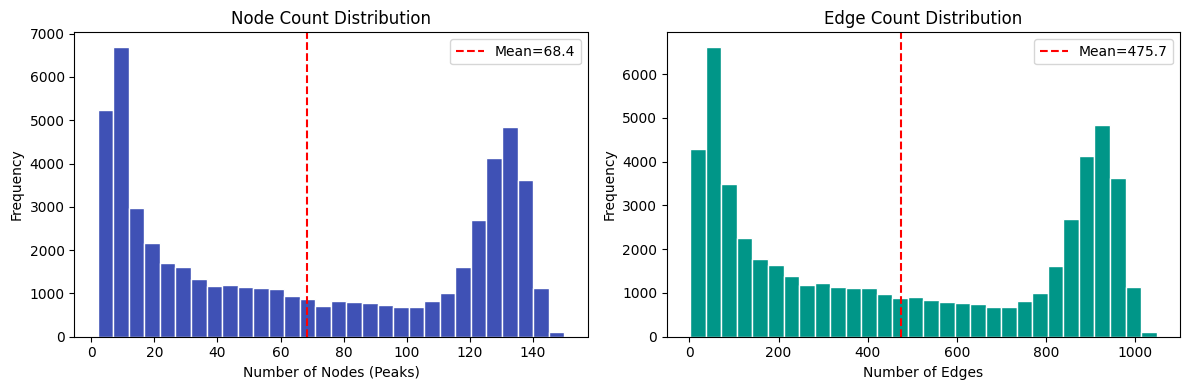

In [44]:
# Compute graph-level statistics
num_nodes_list = [g.x.shape[0] for g in graph_dataset]
num_edges_list = [g.edge_index.shape[1] for g in graph_dataset]

print("Graph Dataset Statistics:")
print(f"  Total graphs:      {len(graph_dataset)}")
print(f"  Avg nodes/graph:   {np.mean(num_nodes_list):.1f} ± {np.std(num_nodes_list):.1f}")
print(f"  Avg edges/graph:   {np.mean(num_edges_list):.1f} ± {np.std(num_edges_list):.1f}")
print(f"  Min/Max nodes:     {np.min(num_nodes_list)} / {np.max(num_nodes_list)}")
print(f"  Node features:     {graph_dataset[0].x.shape[1]}")

# Plot distributions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(num_nodes_list, bins=30, color='#3F51B5', edgecolor='white')
ax1.set_xlabel('Number of Nodes (Peaks)')
ax1.set_ylabel('Frequency')
ax1.set_title('Node Count Distribution')
ax1.axvline(np.mean(num_nodes_list), color='red', linestyle='--', label=f'Mean={np.mean(num_nodes_list):.1f}')
ax1.legend()

ax2.hist(num_edges_list, bins=30, color='#009688', edgecolor='white')
ax2.set_xlabel('Number of Edges')
ax2.set_ylabel('Frequency')
ax2.set_title('Edge Count Distribution')
ax2.axvline(np.mean(num_edges_list), color='red', linestyle='--', label=f'Mean={np.mean(num_edges_list):.1f}')
ax2.legend()

plt.tight_layout()
plt.show()

### 5.3 Train/Test Split & DataLoaders

In [45]:
# Split into train and test sets
train_graphs, test_graphs = train_test_split(
    graph_dataset, 
    test_size=CONFIG['test_size'], 
    random_state=CONFIG['seed']
)

train_loader = DataLoader(train_graphs, batch_size=CONFIG['batch_size'], shuffle=True)
test_loader = DataLoader(test_graphs, batch_size=CONFIG['batch_size'], shuffle=False)

print(f"Train set: {len(train_graphs)} graphs")
print(f"Test set:  {len(test_graphs)} graphs")
print(f"Batch size: {CONFIG['batch_size']}")

Train set: 43584 graphs
Test set:  10897 graphs
Batch size: 64


---
## 6. PeakGAT Model Architecture

The model consists of:
1. **3 GAT layers** with multi-head attention (4 heads each) + ELU activation
2. **Global pooling**: Mean + Max pooling concatenated → 128-dim graph embedding
3. **MLP classifier**: Linear → BatchNorm → ReLU → Dropout → Linear → output logits

In [46]:
class PeakGAT(nn.Module):
    """
    Peak-Based Graph Attention Network for seismic wildlife classification.
    
    Architecture:
        3 × GATConv (multi-head) → Global Mean+Max Pool → MLP Classifier
    """
    def __init__(self, num_node_features, num_classes):
        super(PeakGAT, self).__init__()
        
        hidden = CONFIG['hidden_dim']
        heads = CONFIG['heads']
        
        # Multi-head attention GAT layers
        self.gat1 = GATConv(num_node_features, hidden, heads=heads, concat=False)
        self.gat2 = GATConv(hidden, hidden, heads=heads, concat=False)
        self.gat3 = GATConv(hidden, hidden, heads=heads, concat=False)
        
        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden),  # *2 because we concat mean and max pool
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
            nn.Dropout(CONFIG['dropout']),
            nn.Linear(hidden, num_classes)
        )
    
    def forward(self, x, edge_index, batch):
        # 1. Node embeddings via GAT
        h = F.elu(self.gat1(x, edge_index))
        h = F.elu(self.gat2(h, edge_index))
        h = self.gat3(h, edge_index)
        
        # 2. Global graph pooling (mean + max → captures average and extreme behaviors)
        h_mean = global_mean_pool(h, batch)
        h_max = global_max_pool(h, batch)
        h_graph = torch.cat([h_mean, h_max], dim=1)
        
        # 3. Classification
        return self.classifier(h_graph)


# Instantiate the model
num_node_features = 5  # From our 5D feature extraction
model = PeakGAT(num_node_features=num_node_features, num_classes=num_classes).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print(f"\nTotal parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

PeakGAT(
  (gat1): GATConv(5, 64, heads=4)
  (gat2): GATConv(64, 64, heads=4)
  (gat3): GATConv(64, 64, heads=4)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)

Total parameters:     44,420
Trainable parameters: 44,420


---
## 7. Training

- **Loss:** CrossEntropyLoss
- **Optimizer:** Adam (lr=0.001, weight_decay=1e-4)
- **Scheduler:** ReduceLROnPlateau (patience=5, factor=0.5)
- **Checkpointing:** Best model saved automatically

In [47]:
# ── Training & evaluation functions ──

def train_epoch(model, loader, optimizer, criterion):
    """Run one training epoch."""
    model.train()
    total_loss, correct = 0, 0
    for data in loader:
        data = data.to(device)
        optimizer.zero_grad()
        out = model(data.x, data.edge_index, data.batch)
        loss = criterion(out, data.y)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * data.num_graphs
        pred = out.argmax(dim=1)
        correct += int((pred == data.y).sum())
    
    return total_loss / len(loader.dataset), correct / len(loader.dataset)


def evaluate(model, loader):
    """Evaluate model on a dataset."""
    model.eval()
    correct = 0
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            out = model(data.x, data.edge_index, data.batch)
            pred = out.argmax(dim=1)
            correct += int((pred == data.y).sum())
            
            all_preds.extend(pred.cpu().numpy())
            all_labels.extend(data.y.cpu().numpy())
    
    return correct / len(loader.dataset), all_preds, all_labels

print("Training and evaluation functions defined.")

Training and evaluation functions defined.


In [58]:
# ── Compute class weights for the filtered top-4 dataset ──
from collections import Counter

train_labels = [g.y.item() for g in train_graphs]
class_counts = Counter(train_labels)
total_train = len(train_labels)

class_weights = torch.zeros(num_classes)
for cls, count in class_counts.items():
    class_weights[cls] = total_train / (num_classes * count)
class_weights = class_weights.to(device)

print("Class weights:")
for i in range(num_classes):
    print(f"  Class {i}: weight={class_weights[i]:.2f} (n={class_counts.get(i, 0)})")

# ── Re-initialize model ──
model = PeakGAT(num_node_features=5, num_classes=num_classes).to(device)

# ── Training with weighted loss ──
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay'])
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5)

history = {'train_loss': [], 'train_acc': [], 'test_acc': []}
best_test_acc = 0

print("\nStarting Training (top-4 classes + weighted loss)...")
print(f"{'Epoch':>6} | {'Loss':>8} | {'Train Acc':>10} | {'Test Acc':>10}")
print("-" * 45)

for epoch in range(1, CONFIG['epochs'] + 1):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    test_acc, _, _ = evaluate(model, test_loader)
    scheduler.step(test_acc)
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['test_acc'].append(test_acc)
    
    if test_acc > best_test_acc:
        best_test_acc = test_acc
        torch.save(model.state_dict(), 'PROJECT/best_gat_model.pth')
    
    if epoch % 5 == 0 or epoch == 1:
        print(f"{epoch:>6} | {train_loss:>8.4f} | {train_acc:>10.4f} | {test_acc:>10.4f}")

print("-" * 45)
print(f"\n🏆 Training Complete! Best Test Accuracy: {best_test_acc:.4f}")


Class weights:
  Class 0: weight=8.64 (n=1261)
  Class 1: weight=0.28 (n=39212)
  Class 2: weight=27.24 (n=400)
  Class 3: weight=4.02 (n=2711)

Starting Training (top-4 classes + weighted loss)...
 Epoch |     Loss |  Train Acc |   Test Acc
---------------------------------------------
     1 |   1.3072 |     0.5121 |     0.1835
     5 |   1.2107 |     0.5244 |     0.5535
    10 |   1.1562 |     0.5404 |     0.5158
    15 |   1.1028 |     0.5461 |     0.5803
    20 |   1.0561 |     0.5576 |     0.5683
    25 |   1.0437 |     0.5705 |     0.5914
    30 |   1.0291 |     0.5678 |     0.5959
    35 |   1.0293 |     0.5700 |     0.6127
    40 |   1.0232 |     0.5673 |     0.6045
    45 |   1.0186 |     0.5716 |     0.6083
    50 |   1.0213 |     0.5750 |     0.6150
    55 |   1.0159 |     0.5695 |     0.6076
    60 |   1.0136 |     0.5656 |     0.5796
    65 |   1.0197 |     0.5678 |     0.5910
    70 |   1.0154 |     0.5671 |     0.6003
    75 |   1.0160 |     0.5642 |     0.5898
    80 |

---
## 8. Training Curves

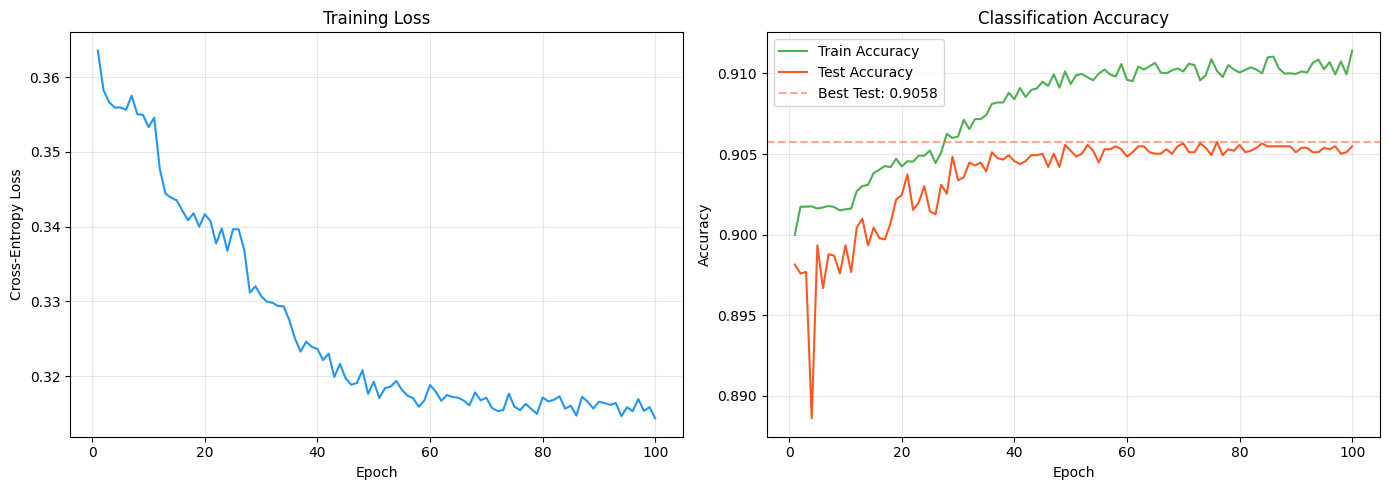

Training curves saved to training_curves.png


In [54]:
# Plot training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history['train_loss']) + 1)

# Loss curve
ax1.plot(epochs_range, history['train_loss'], color='#2196F3', linewidth=1.5)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Cross-Entropy Loss')
ax1.set_title('Training Loss')
ax1.grid(True, alpha=0.3)

# Accuracy curves
ax2.plot(epochs_range, history['train_acc'], color='#4CAF50', linewidth=1.5, label='Train Accuracy')
ax2.plot(epochs_range, history['test_acc'], color='#FF5722', linewidth=1.5, label='Test Accuracy')
ax2.axhline(best_test_acc, color='#FF5722', linestyle='--', alpha=0.5, 
            label=f'Best Test: {best_test_acc:.4f}')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('Classification Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=300, bbox_inches='tight')
plt.show()
print("Training curves saved to training_curves.png")

---
## 9. Evaluation & Metrics

Load the best saved model and generate the full classification report and confusion matrix.

In [55]:
# Load best model
model.load_state_dict(torch.load('PROJECT/best_gat_model.pth'))

# Final evaluation
test_acc, preds, true_labels = evaluate(model, test_loader)

print(f"Best Model Test Accuracy: {test_acc:.4f}")
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(true_labels, preds))

Best Model Test Accuracy: 0.9058

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.76      0.15      0.26       352
           1       0.91      1.00      0.95      9763
           2       0.00      0.00      0.00       108
           3       0.71      0.15      0.24       674

    accuracy                           0.91     10897
   macro avg       0.59      0.32      0.36     10897
weighted avg       0.88      0.91      0.87     10897



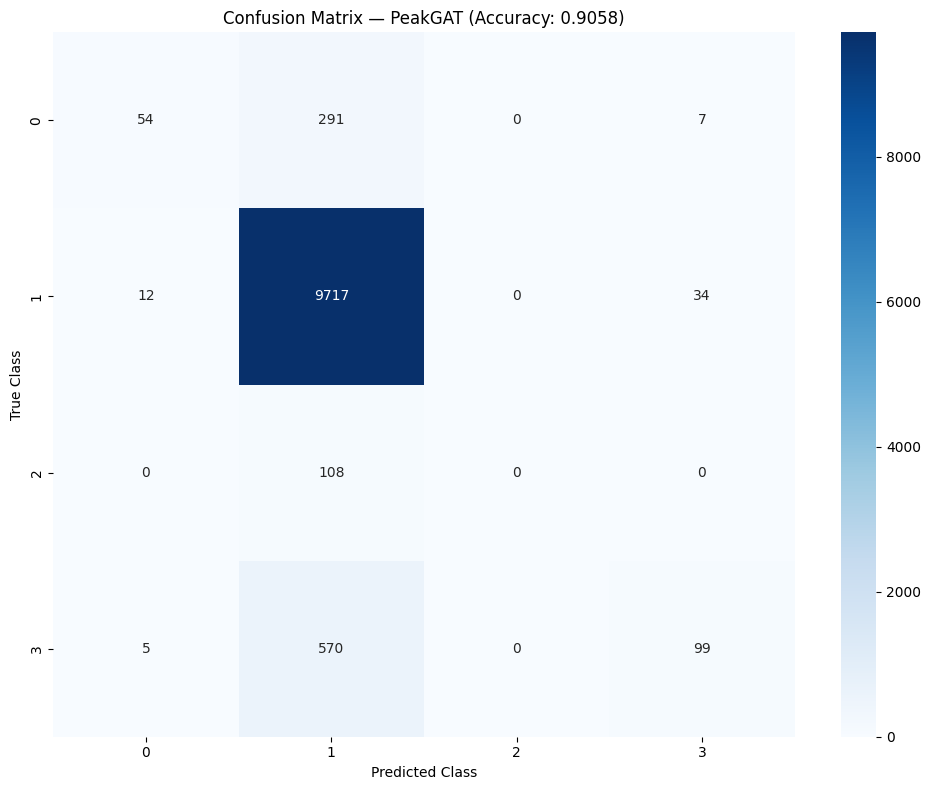

Confusion matrix saved to confusion_matrix.png


In [56]:
# Confusion matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(true_labels, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=range(num_classes), 
            yticklabels=range(num_classes))
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.title(f'Confusion Matrix — PeakGAT (Accuracy: {test_acc:.4f})')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print("Confusion matrix saved to confusion_matrix.png")

---
## 10. Summary

Print a final summary of the experiment configuration and results.

In [57]:
print("=" * 60)
print("EXPERIMENT SUMMARY")
print("=" * 60)
print(f"")
print(f"Dataset:               {CONFIG['data_file']}")
print(f"Total samples:         {len(spectrograms)}")
print(f"Valid graphs:          {len(graph_dataset)}")
print(f"Number of classes:     {num_classes}")
print(f"")
print(f"Peak Detection:")
print(f"  Prominence:          {CONFIG['prominence']}")
print(f"  Min distance:        {CONFIG['distance']}")
print(f"  Avg nodes/graph:     {np.mean(num_nodes_list):.1f}")
print(f"")
print(f"Graph Construction:")
print(f"  Edge types:          Temporal + k-NN (k={CONFIG['k_neighbors']})")
print(f"  Avg edges/graph:     {np.mean(num_edges_list):.1f}")
print(f"")
print(f"Model:")
print(f"  Architecture:        PeakGAT (3-layer, {CONFIG['heads']}-head attention)")
print(f"  Hidden dim:          {CONFIG['hidden_dim']}")
print(f"  Total parameters:    {total_params:,}")
print(f"  Dropout:             {CONFIG['dropout']}")
print(f"")
print(f"Training:")
print(f"  Epochs:              {CONFIG['epochs']}")
print(f"  Learning rate:       {CONFIG['learning_rate']}")
print(f"  Batch size:          {CONFIG['batch_size']}")
print(f"")
print(f"Results:")
print(f"  Best Test Accuracy:  {best_test_acc:.4f}")
print(f"")
print("=" * 60)

EXPERIMENT SUMMARY

Dataset:               PROJECT/dset_allspec_150_chunks_clean.nc
Total samples:         70637
Valid graphs:          54481
Number of classes:     4

Peak Detection:
  Prominence:          0.05
  Min distance:        10
  Avg nodes/graph:     68.4

Graph Construction:
  Edge types:          Temporal + k-NN (k=5)
  Avg edges/graph:     475.7

Model:
  Architecture:        PeakGAT (3-layer, 4-head attention)
  Hidden dim:          64
  Total parameters:    44,420
  Dropout:             0.4

Training:
  Epochs:              100
  Learning rate:       0.001
  Batch size:          64

Results:
  Best Test Accuracy:  0.9058

